In [115]:
import warnings
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# Suppress ARIMA warnings and all warnings
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.filterwarnings("ignore")

In [116]:

# Load your data
df = pd.read_csv('complaintdata.csv')

df.head(10)

,id1,category,details,pnr,startTime,endTime,status,staffId,ticket id,ticketDetails,feedback,rating,sentiment,metadata,media
0,1,damage_seat,Seat cushion is torn and uncomfortable.,1234567890,2024-10-10 08:15:00,2024-10-10 09:45:00,completed,staff001,NaN,NaN,The seat was repaired quickly and is now comfo...,4,0.939621,image001.jpg,video001.mp4
1,2,food,Food served was cold and stale.,9876543210,2024-10-11 10:30:00,2024-10-11 12:00:00,completed,staff002,NaN,NaN,"The food quality was below expectations, but i...",2,0.643788,image002.jpg,video002.mp4
2,3,unhygenic_compartment,The compartment was dirty with trash all around.,1928374650,2024-10-12 14:00:00,2024-10-12 15:30:00,completed,staff003,NaN,NaN,Cleanliness improved after the complaint was a...,3,0.593084,image003.jpg,video003.mp4
3,5,violence,There was a fight between passengers in my coach.,2233445566,2024-10-14 18:45:00,2024-10-14 20:00:00,completed,staff005,NaN,NaN,"The situation was handled quickly, but it was ...",3,0.806618,image005.jpg,video005.mp4
4,6,unhygenic_toilet,Toilet was extremely dirty and lacked soap.,3344556677,2024-10-15 09:00:00,2024-10-15 10:20:00,completed,staff006,NaN,NaN,Toilet was cleaned and stocked with soap right...,4,0.729540,image006.jpg,video006.mp4
5,7,management,The train was delayed by 2 hours and no announ...,4455667788,2024-10-16 11:00:00,2024-10-16 12:30:00,completed,staff007,NaN,NaN,"The delay was acknowledged, but communication ...",2,0.247223,image007.jpg,video007.mp4
6,8,Electricity,The AC in the compartment stopped working.,5566778899,2024-10-17 13:00:00,2024-10-17 14:45:00,completed,staff008,NaN,NaN,"AC was fixed quickly, but the temperature was ...",3,0.361886,image008.jpg,video008.mp4
7,9,unhygenic_toilet,Washbasin was clogged and dirty.,6677889900,2024-10-18 15:00:00,2024-10-18 16:00:00,completed,staff009,NaN,NaN,The washbasin was cleared and cleaned quickly.,5,0.690079,image009.jpg,video009.mp4
8,10,damage_window,The window was broken and couldn't be closed.,7788990011,2024-10-19 07:45:00,2024-10-19 09:00:00,completed,staff010,NaN,NaN,The window was repaired promptly and was secur...,4,0.741597,image010.jpg,video010.mp4
9,11,damage_seat,The seat was uncomfortable and lacked proper s...,9988776655,2024-10-20 08:00:00,2024-10-20 09:30:00,completed,staff011,NaN,NaN,The seat was fixed but could have been more co...,3,0.800767,image011.jpg,video011.mp4


<Figure size 1200x600 with 0 Axes>

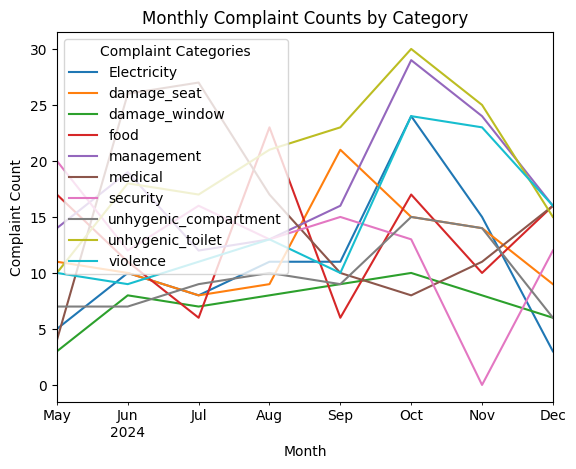

In [117]:

# Step 1: Convert `startTime` to datetime format
df['startTime'] = pd.to_datetime(df['startTime'])

# Step 2: Resample data to get monthly complaint counts by category
df['month'] = df['startTime'].dt.to_period('M')
complaint_counts = df.groupby(['month', 'category']).size().unstack(fill_value=0)

# Visualize the monthly complaint count trends by category
plt.figure(figsize=(12, 6))
complaint_counts.plot(title="Monthly Complaint Counts by Category")
plt.xlabel("Month")
plt.ylabel("Complaint Count")
plt.legend(title="Complaint Categories")
plt.show()


In [118]:

def forecast_category(category_data, periods=3):
    # Step 3: Check if there's enough data for ARIMA
    if len(category_data) < 5 or category_data.sum() == 0:
        print(f"Not enough data to forecast for category {category_data.name}.")
        return [0] * periods  # Return zeros if there's insufficient data

    # Step 4: Plot the data to observe the trend
    category_data.plot(title=f"Time Series for {category_data.name}")
    plt.show()
    
    # Step 5: Fit ARIMA model and forecast with error handling
    try:
        # Check if the data has enough variation for ARIMA
        if category_data.nunique() == 1:
            print(f"No variation in data for category {category_data.name}.")
            return [category_data.iloc[-1]] * periods  # Predict a flat line if no variation

        # Fit ARIMA model
        model = ARIMA(category_data, order=(1, 1, 1))
        model_fit = model.fit()
        forecast = model_fit.forecast(steps=periods)
        print(f"Forecast for {category_data.name}: {forecast.values}")
        return forecast.values
    except Exception as e:
        print(f"Error forecasting {category_data.name}: {e}")
        return [0] * periods  # Return zeros in case of error


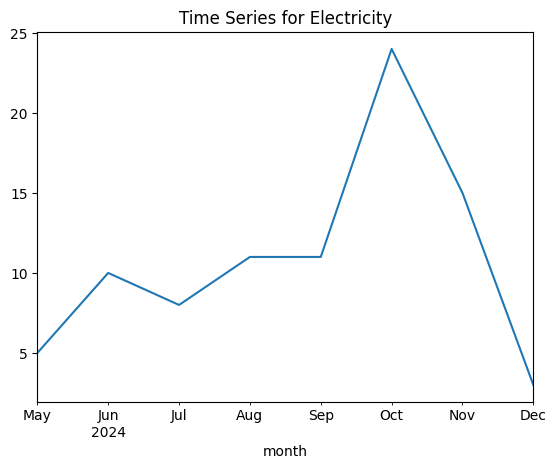

Forecast for Electricity: [7.32242839 8.96193536 9.58380409]


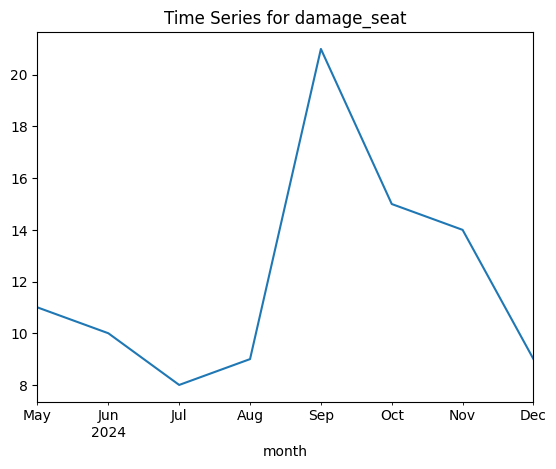

Forecast for damage_seat: [10.99366577 11.61989002 11.81659141]


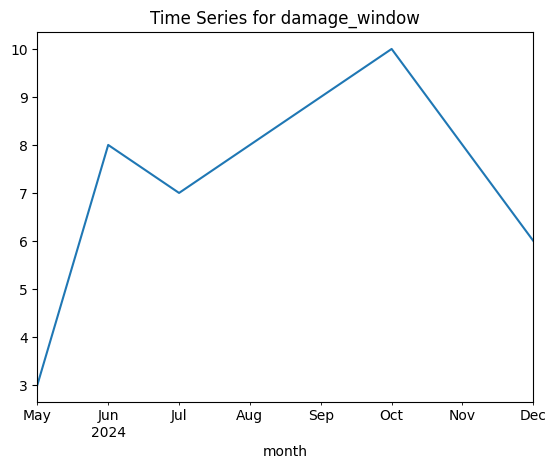

Forecast for damage_window: [5.9770755  5.99474267 5.98112715]


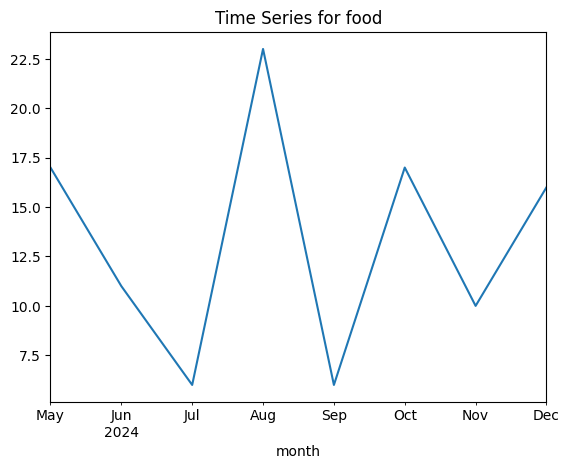

Forecast for food: [10.74252612 14.34981506 11.87476073]


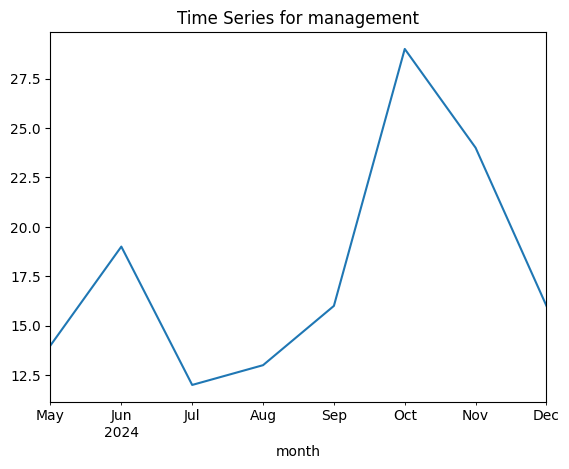

Forecast for management: [16.84186997 17.19183014 17.33730643]


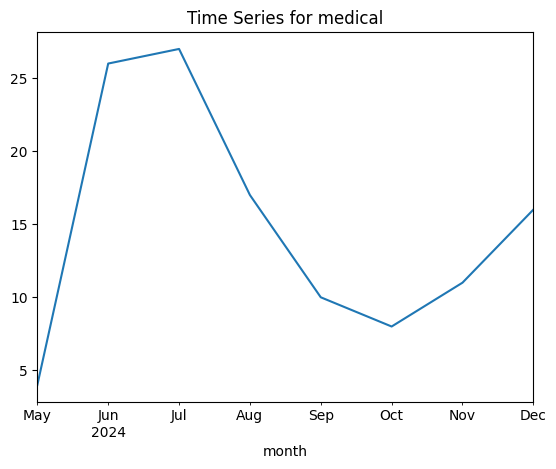

Forecast for medical: [19.92485389 21.99324834 23.08329035]


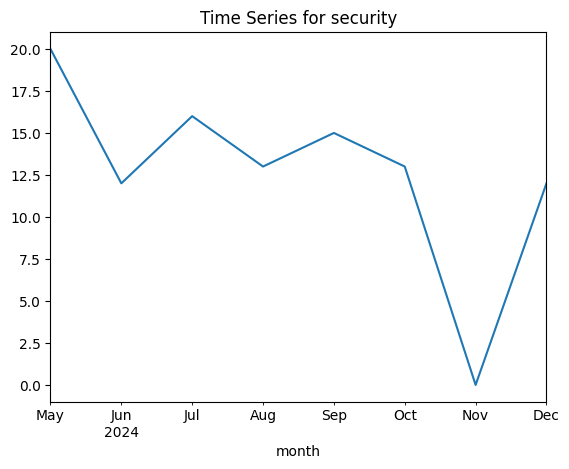

Forecast for security: [5.78208663 8.74057554 7.33292379]


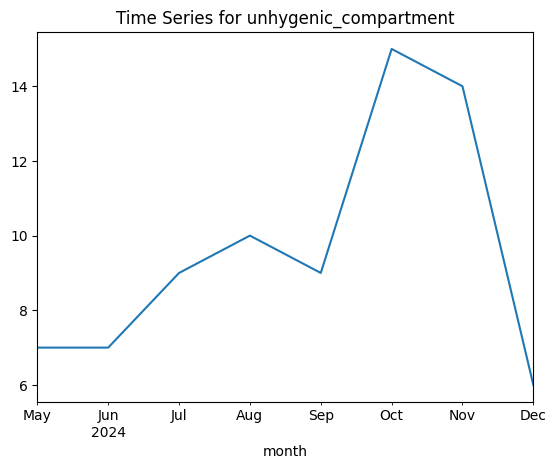

Forecast for unhygenic_compartment: [5.0079735  5.464905   5.25444047]


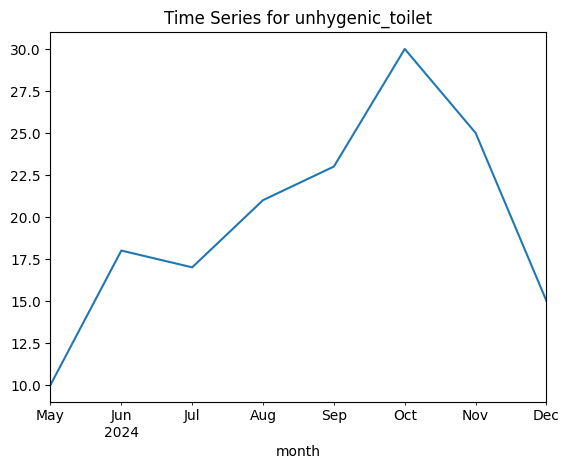

Forecast for unhygenic_toilet: [13.242139   13.21160136 13.21107086]


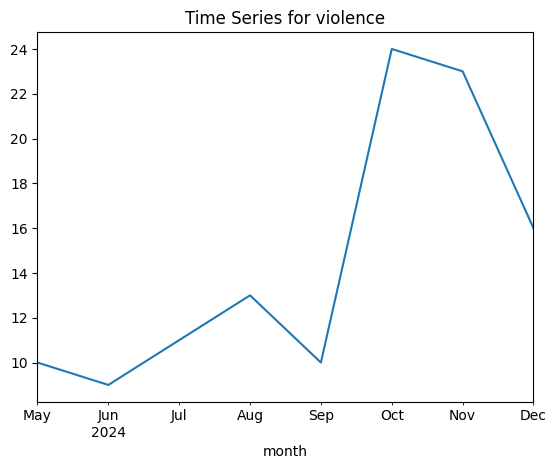

Forecast for violence: [15.23273382 14.77438116 14.50056855]


In [119]:

# Step 6: Forecast for each category and store results
future_predictions = {}
for category in complaint_counts.columns:
    category_data = complaint_counts[category]
    forecast = forecast_category(category_data)
    future_predictions[category] = forecast  # Store all period forecasts



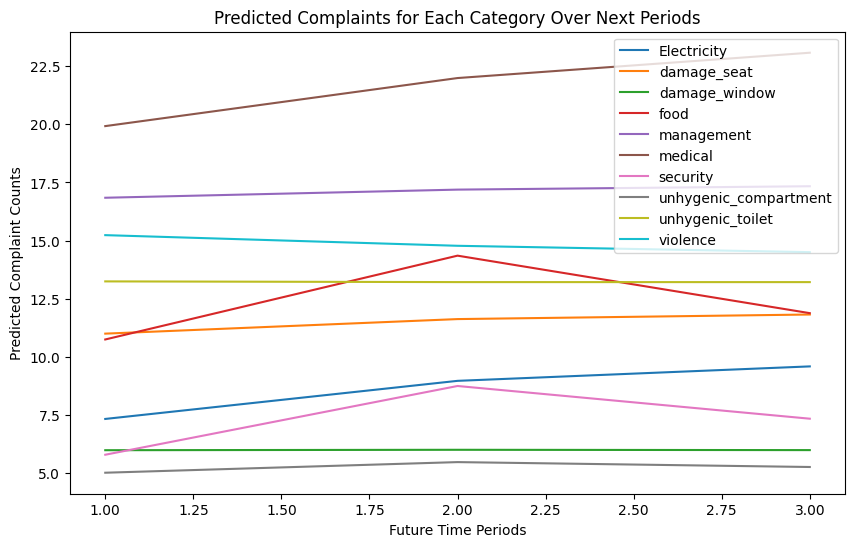

In [120]:

# Step 7: Visualize Forecast Results for Each Category
plt.figure(figsize=(10, 6))
for category, forecast in future_predictions.items():
    if sum(forecast) > 0:  # Only plot categories with valid forecasts
        plt.plot(range(1, len(forecast) + 1), forecast, label=category)
plt.legend()
plt.title("Predicted Complaints for Each Category Over Next Periods")
plt.xlabel("Future Time Periods")
plt.ylabel("Predicted Complaint Counts")
plt.show()


In [121]:

# Step 8: Determine the category with the highest forecasted complaints
most_likely_issue = max(future_predictions, key=lambda k: sum(future_predictions[k]))
print("Most likely issue to occur in the future:", most_likely_issue)


Most likely issue to occur in the future: medical


In [122]:

# Step 9: Print the forecasted dates
last_month = complaint_counts.index[-1]  # Get the last month in the data
last_month_timestamp = last_month.start_time  # Convert period to timestamp

print("Forecast Dates:")
for i in range(3):  # For the next 3 months
    forecast_date = (last_month_timestamp + pd.DateOffset(months=i+1)).strftime('%Y-%m')
    print(f"Month {i+1}: {forecast_date} - Predicted Complaints: {future_predictions[most_likely_issue][i]}")


Forecast Dates:
Month 1: 2025-01 - Predicted Complaints: 19.924853886197006
Month 2: 2025-02 - Predicted Complaints: 21.993248340226938
Month 3: 2025-03 - Predicted Complaints: 23.08329034981808
